# Skripsi ASR — IQRO Huruf Hijaiyah Tunggal (29 Kelas): Notebook Master 12 Eksperimen — SPLIT SPEAKER-INDEPENDENT

**Split speaker-independent** (`SPLIT_MODE="speaker"`): seluruh rekaman satu speaker hanya berada di SATU bagian (train / val / test), sehingga hasil test mengukur generalisasi ke ORANG BARU.

**Khusus Hijaiyah:** audio sangat pendek (0,5–2,9 s) → tanpa trimming, padding hening 0,6 s per sisi (= 0,5 s 'Dataset Hijaiyah Padded' + 0,1 s micro-pad), frame fitur 10 ms (hop 160, N_FFT 512, win 400), LR tunggal 3e-5.
Nomor urut label dibuang (`02-BA` → `ba`), kecuali `01-A` (alif) dan `28-A` (hamzah) yang bertabrakan → `01a` dan `28a` (tetap 29 kelas).

**Matriks eksperimen** = 4 model fondasi × 3 skenario fitur:

| Model | Hugging Face ID | Kepala |
|---|---|---|
| `wav2vec2` | facebook/wav2vec2-base | CTC (karakter) |
| `hubert` | facebook/hubert-base-ls960 | CTC (karakter) |
| `wavlm` | microsoft/wavlm-base-plus | CTC (karakter) |
| `whisper` | openai/whisper-tiny | Seq2Seq (tokenizer Whisper) |

| Skenario | Masukan |
|---|---|
| `Skenario_1` | Baseline: raw waveform 16 kHz (CTC) / log-Mel bawaan `WhisperProcessor` (Whisper) |
| `Skenario_2` | Fusi MFCC kustom (20 dim) via Adapter Layer |
| `Skenario_3` | Fusi log-Mel kustom (80 dim) via Adapter Layer |

**Dependensi** (dipasang otomatis di CELL 1):
`pip install transformers accelerate datasets jiwer librosa soundfile torchaudio openpyxl seaborn scikit-learn tqdm`

**Cara pakai:** atur `CONFIG` di CELL 2 → *Runtime > Run all*. Ke-12 eksperimen berjalan dalam satu run:
CELL 8A = Skenario 1 (4 model), CELL 8B = Skenario 2 (4 model), CELL 8C = Skenario 3 (4 model), lalu CELL 9 merekap.
Jika runtime terputus, cukup *Run all* lagi: model yang sudah punya `eval_metrics.json` di-SKIP,
model yang terputus di-RESUME dari checkpoint terakhir. Skenario tertentu bisa dinonaktifkan lewat `SCENARIOS_TO_RUN`.

Format nama file dataset: `[ID]_[Gender]_[LabelBacaan]_[Repetisi].wav` → contoh `S01_M_01-AKALA_1.wav`.

In [ ]:
# ============================================================
# [CELL 1] DEPENDENSI & GPU ENVIRONMENT
# ============================================================
import subprocess, sys

PIP_PACKAGES = [
    'transformers', 'accelerate', 'datasets', 'jiwer', 'librosa', 'soundfile',
    'torchaudio', 'openpyxl', 'seaborn', 'scikit-learn', 'tqdm',
]
# Tanpa '-U' agar versi torch/torchaudio bawaan Colab tidak ikut ter-upgrade (mencegah mismatch CUDA).
subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', *PIP_PACKAGES], check=True)

import torch, transformers, librosa
print('Python      :', sys.version.split()[0])
print('torch       :', torch.__version__, '| CUDA build:', torch.version.cuda)
print('transformers:', transformers.__version__)
print('librosa     :', librosa.__version__)
if torch.cuda.is_available():
    prop = torch.cuda.get_device_properties(0)
    print(f'GPU         : {prop.name} | VRAM = {prop.total_memory / 1024**3:.1f} GB')
    try:
        print(subprocess.run(['nvidia-smi'], capture_output=True, text=True).stdout)
    except FileNotFoundError:
        pass
else:
    print('[PERINGATAN] GPU tidak terdeteksi. Aktifkan: Runtime > Change runtime type > T4 GPU.')

Python      : 3.13.16
torch       : 2.14.1+cu130 | CUDA build: 13.0
transformers: 5.22.1
librosa     : 0.11.0
GPU         : NVIDIA L4 | VRAM = 22.0 GB
Wed Nov 11 10:49:00 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  NVIDIA L4                      Off |   00000000:00:03.0 Off |                    0 |
| N/A   33C    P8             13W /   72W |       3MiB /  23034MiB |      0%     

In [ ]:
# ============================================================
# [CELL 2] MOUNT DRIVE & MASTER CONFIGURATION SWITCH
# ============================================================
import os, re, gc, json, time, random, shutil, unicodedata, traceback, warnings
from pathlib import Path
from datetime import datetime
from dataclasses import dataclass
from typing import Any, Dict, List, Optional

import numpy as np
import pandas as pd
import librosa
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm.auto import tqdm

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader

from sklearn.model_selection import train_test_split, GroupShuffleSplit
from sklearn.metrics import confusion_matrix

from transformers import (
    AutoModel, AutoFeatureExtractor, Wav2Vec2CTCTokenizer,
    WhisperProcessor, WhisperForConditionalGeneration,
    get_linear_schedule_with_warmup, get_constant_schedule_with_warmup,
)

try:
    from IPython.display import display
except ImportError:
    display = print

warnings.filterwarnings('ignore')
os.environ['TOKENIZERS_PARALLELISM'] = 'false'

# ---------- Mount Google Drive ----------
try:
    from google.colab import drive
    drive.mount('/content/drive')
except ImportError:
    print('Bukan di Google Colab -> mount Drive dilewati.')

# ============================================================
# PANEL KONTROL UTAMA (ubah di sini saja)
# ============================================================
CONFIG = {
    "SCENARIOS_TO_RUN": ["Skenario_1", "Skenario_2", "Skenario_3"],  # dijalankan di CELL 8A / 8B / 8C
    "ACTIVE_MODELS": ["wav2vec2", "hubert", "wavlm", "whisper"],  # Model yang akan di-run (urut)
    "DATASET_PATH": "/content/drive/MyDrive/Dataset/Dataset Hijaiyah",  # dataset ASLI; padding otomatis via ADV["PAD_SECONDS"]
    "OUTPUT_DIR": "/content/drive/MyDrive/Output_Skripsi_Hijaiyah_Speaker",  # SPEAKER-INDEPENDENT: terpisah dari hasil split stratified
    "EPOCHS": 30,                                           # HIJAIYAH: data kecil & audio pendek -> CTC butuh lebih lama keluar dari fase blank
    "BATCH_SIZE": 8,
    "LR": 3e-5,                                             # LR backbone pretrained (SSL & Whisper)
    "SEED": 42,
}

# ---------- Konfigurasi lanjutan (default sudah aman; ubah bila perlu) ----------
ADV = {
    # Data & split
    "LOCAL_DATA_DIR": "/content/dataset_iqro_hijaiyah",      # salinan lokal dataset (I/O jauh lebih cepat dari Drive)
    "LOCAL_CACHE_DIR": "/content/feature_cache_hijaiyah",    # cache waveform & fitur .npy (lokal, dibangun ulang otomatis)
    "SPLIT_MODE": "speaker",                        # SPEAKER-INDEPENDENT: speaker di test/val tidak pernah muncul di train
    "TEST_SIZE": 0.20,
    "VAL_SIZE": 0.10,                               # porsi dari total; dipakai memilih checkpoint terbaik
    "STRIP_INDEX_PREFIX": "auto",                   # 'auto': nomor dibuang ('02-BA'->'ba'), KECUALI label yang bertabrakan
                                                    #   (01-A alif & 28-A hamzah -> '01a' & '28a') agar tetap 29 kelas. True = buang semua, False = pertahankan semua
    "EXPECTED_NUM_CLASSES": 29,                     # Dataset Hijaiyah: 29 kelas (~860 sampel, 10 speaker)

    # Audio
    "SR": 16000,
    "MAX_SECONDS": 5.0,                             # durasi asli maks 2,9 s + padding 2 x 0,6 s
    "TRIM_SILENCE": False,                          # HIJAIYAH: dimatikan agar onset konsonan lemah ('ain, ha) tidak terpotong
    "TRIM_TOP_DB": 30,
    "PAD_SECONDS": 0.60,                            # HIJAIYAH: 0,5 s (setara Dataset Hijaiyah Padded) + 0,1 s micro-pad
    "N_MFCC": 20,
    "N_MELS": 80,
    "SSL_N_FFT": 512, "SSL_WIN": 400, "SSL_HOP": 160,  # HIJAIYAH [MOD 1]: frame 10 ms (2x lebih rapat), diinterpolasi ke frame SSL
    "WHISPER_N_FFT": 400, "WHISPER_WIN": 400, "WHISPER_HOP": 160,  # 10 ms = frame-rate input Whisper
    "WHISPER_FRAMES": 3000,                         # Whisper wajib 3000 frame (30 s)

    # Training
    "HEAD_LR": 3e-4,                                # LR layer baru (adapter + CTC head); 3e-5 terlalu kecil -> CTC macet di output kosong
    "WEIGHT_DECAY": 1e-6,
    "WARMUP_RATIO": 0.05,
    "LR_SCHEDULE": "constant",                      # HIJAIYAH: 'constant' = warmup lalu LR tetap (seperti notebook lama) | 'linear' = turun ke 0
    "GRAD_CLIP": 5.0,
    "FREEZE_EPOCHS": 3,                             # SSL: epoch awal hanya adapter + head yang dilatih
    "FREEZE_FEATURE_ENCODER": True,                 # SSL: CNN feature encoder tetap beku
    "EARLY_STOP_PATIENCE": 10,                      # None = nonaktif
    "CHECKPOINT_EVERY": 1,                          # simpan checkpoint resume tiap N epoch
    "KEEP_LATEST_CHECKPOINT_AFTER_DONE": False,     # False = hapus checkpoint resume (~1 GB) setelah training selesai
    "NUM_WORKERS": 2,

    # Whisper
    "WHISPER_LANGUAGE": None,                       # None = otomatis ('arabic' jika label beraksara Arab, selain itu 'indonesian')
    "WHISPER_TASK": "transcribe",
    "WHISPER_FUSION_MODE": "add",                   # 'add' = fusi (log-Mel Whisper + adapter) | 'replace' = adapter menggantikan log-Mel
    "WHISPER_MAX_NEW_TOKENS": 32,
    "WHISPER_FREEZE_ENCODER": False,

    # Metrik PER: digraf transliterasi dihitung 1 fonem
    "PHONE_DIGRAPHS": ['kh', 'sy', 'sh', 'ts', 'th', 'dz', 'dh', 'zh', 'gh'],

}

# ---------- Registri model & skenario ----------
MODEL_REGISTRY = {
    'wav2vec2': {'hf_id': 'facebook/wav2vec2-base',     'family': 'ctc'},
    'hubert':   {'hf_id': 'facebook/hubert-base-ls960', 'family': 'ctc'},
    'wavlm':    {'hf_id': 'microsoft/wavlm-base-plus',  'family': 'ctc'},
    'whisper':  {'hf_id': 'openai/whisper-tiny',        'family': 'whisper'},
}
SCENARIOS = {
    'Skenario_1': {'feature': None,     'dim': None,           'desc': 'Baseline (raw waveform / log-Mel Whisper)'},
    'Skenario_2': {'feature': 'mfcc',   'dim': ADV['N_MFCC'],  'desc': 'Fusi MFCC (20 dim)'},
    'Skenario_3': {'feature': 'logmel', 'dim': ADV['N_MELS'],  'desc': 'Fusi log-Mel (80 dim)'},
}

SCENARIOS_TO_RUN = list(CONFIG['SCENARIOS_TO_RUN'])
ACTIVE_MODELS = list(CONFIG['ACTIVE_MODELS'])
_bad_sc = [s for s in SCENARIOS_TO_RUN if s not in SCENARIOS]
assert not _bad_sc, f'Skenario tidak dikenal: {_bad_sc}. Pilihan: {list(SCENARIOS)}'
CURRENT_SCENARIO = SCENARIOS_TO_RUN[0] if SCENARIOS_TO_RUN else 'Skenario_1'   # diganti otomatis oleh activate_scenario()
_unknown = [m for m in ACTIVE_MODELS if m not in MODEL_REGISTRY]
assert not _unknown, f'Model tidak dikenal: {_unknown}. Pilihan: {list(MODEL_REGISTRY)}'
assert ADV['WHISPER_FUSION_MODE'] in ('add', 'replace')

# ---------- Struktur folder dinamis: {OUTPUT_DIR}/{CURRENT_SCENARIO}/{model_name}/ ----------
OUTPUT_DIR   = Path(CONFIG['OUTPUT_DIR'])
SHARED_DIR   = OUTPUT_DIR / '_shared'            # split, vocab, tokenizer, statistik fitur (dipakai semua skenario)

def model_dir(model_key, scenario=None):
    return OUTPUT_DIR / (scenario or CURRENT_SCENARIO) / model_key

for d in [OUTPUT_DIR, SHARED_DIR] + [model_dir(m, s) for s in SCENARIOS_TO_RUN for m in ACTIVE_MODELS]:
    d.mkdir(parents=True, exist_ok=True)

# ---------- Seed & device ----------
def set_seed(seed):
    random.seed(seed); np.random.seed(seed)
    torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)

SEED = CONFIG['SEED']
set_seed(SEED)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
USE_AMP = device.type == 'cuda'
SR = ADV['SR']

with open(OUTPUT_DIR / 'config_snapshot.json', 'w') as f:
    json.dump({'CONFIG': CONFIG, 'ADV': ADV, 'saved_at': datetime.now().isoformat(timespec='seconds')}, f, indent=2)

print('Device          :', device, '| AMP fp16:', USE_AMP)
print('Skenario        :', [f"{s} ({SCENARIOS[s]['desc']})" for s in SCENARIOS_TO_RUN])
print('Model aktif     :', ACTIVE_MODELS)
print(f'Total eksperimen: {len(SCENARIOS_TO_RUN) * len(ACTIVE_MODELS)} -> {OUTPUT_DIR}/<Skenario>/<model>/')

Mounted at /content/drive
Device          : cuda | AMP fp16: True
Skenario        : ['Skenario_1 (Baseline (raw waveform / log-Mel Whisper))', 'Skenario_2 (Fusi MFCC (20 dim))', 'Skenario_3 (Fusi log-Mel (80 dim))']
Model aktif     : ['wav2vec2', 'hubert', 'wavlm', 'whisper']
Total eksperimen: 12 -> /content/drive/MyDrive/Output_Skripsi_Hijaiyah_Speaker/<Skenario>/<model>/


In [ ]:
# ============================================================
# [CELL 3] DATA INDEX, SPLIT, VOCABULARY & TOKENIZER (RUN ONCE)
# ============================================================
# Split, vocab CTC, dan WhisperProcessor disimpan permanen di {OUTPUT_DIR}/_shared/.
# Saat runtime baru, semuanya DIMUAT ULANG (bukan dibuat ulang) -> 12 eksperimen memakai split & vocab yang identik.

# ---------- Salin dataset ke runtime lokal (aman jika copy sebelumnya terputus) ----------
DATASET_SRC = Path(CONFIG['DATASET_PATH'])
assert DATASET_SRC.exists(), f'Folder dataset tidak ditemukan: {DATASET_SRC}'
LOCAL_DATA_DIR = Path(ADV['LOCAL_DATA_DIR']) / DATASET_SRC.name
if not LOCAL_DATA_DIR.exists():
    tmp_dir = LOCAL_DATA_DIR.with_name(LOCAL_DATA_DIR.name + '__tmp')
    if tmp_dir.exists():
        shutil.rmtree(tmp_dir)
    print(f'Menyalin dataset ke runtime lokal: {DATASET_SRC} -> {LOCAL_DATA_DIR}')
    shutil.copytree(DATASET_SRC, tmp_dir)
    tmp_dir.rename(LOCAL_DATA_DIR)
else:
    print('Dataset lokal sudah ada:', LOCAL_DATA_DIR)

# ---------- Normalisasi teks: hapus harakat, huruf kecil, buang tanda baca ----------
HARAKAT_RE = re.compile('[ؐ-ًؚ-ٰٟۖ-ۜ۟-۪ۨ-ۭـ]')
ARABIC_LETTER_RE = re.compile('[ء-يٱ-ۓ]')

def normalize_text(text):
    t = unicodedata.normalize('NFC', str(text))
    t = HARAKAT_RE.sub('', t)                                   # huruf Arab tanpa harakat
    t = t.lower()
    t = re.sub('[‘’ʼ`´]', "'", t)                    # variasi apostrof -> '
    t = re.sub(r'[-_]', '', t)
    t = re.sub(r"[^a-z0-9'ء-يٱ-ۓ\s]", ' ', t)  # sisakan huruf Latin, angka (nomor kelas), apostrof, huruf Arab
    return re.sub(r'\s+', ' ', t).strip()

def label_to_text(raw_label):
    t = str(raw_label).strip()
    if ADV['STRIP_INDEX_PREFIX']:
        t = re.sub(r'^\d+[-_ ]*', '', t)
    return normalize_text(t)

def parse_filename(path):
    """[ID]_[Gender]_[LabelBacaan]_[Repetisi].wav -> dict metadata (None jika format salah)."""
    p = Path(path)
    parts = p.stem.split('_')
    if len(parts) < 4:
        return None
    raw_label = '_'.join(parts[2:-1]).strip()
    text = label_to_text(raw_label)
    if not text:
        return None
    return {'filename': p.name, 'speaker_id': parts[0], 'gender': parts[1],
            'raw_label': raw_label, 'text': text, 'repetition': parts[-1]}

_t = parse_filename('S01_M_01-AKALA_1.wav')
assert (_t['speaker_id'], _t['gender'], _t['raw_label'], _t['repetition']) == ('S01', 'M', '01-AKALA', '1'), _t

def local_path(rel_path):
    return str(LOCAL_DATA_DIR / rel_path)

# ---------- Indeks seluruh file .wav ----------
rows, skipped = [], []
for p in sorted(LOCAL_DATA_DIR.rglob('*')):
    if p.suffix.lower() != '.wav':
        continue
    item = parse_filename(p)
    if item is None:
        skipped.append(p.name)
        continue
    item['rel_path'] = str(p.relative_to(LOCAL_DATA_DIR))
    rows.append(item)
if skipped:
    print(f'[PERINGATAN] {len(skipped)} file tidak sesuai format dan dilewati. Contoh: {skipped[:5]}')
df_scan = pd.DataFrame(rows)
assert len(df_scan) > 0, 'Tidak ada file .wav valid di dataset.'

def assign_texts(df):
    """Hitung ulang teks target dari raw_label sesuai ADV['STRIP_INDEX_PREFIX'] SAAT INI (tidak memakai teks lama di CSV).
    Mode 'auto': label yang sama setelah nomor dibuang tetapi nomornya berbeda (mis. 01-A & 28-A) diberi nomor kembali."""
    df = df.copy()
    df['text'] = df['raw_label'].map(label_to_text)
    if ADV['STRIP_INDEX_PREFIX'] == 'auto':
        num = df['raw_label'].str.extract(r'^(\d+)', expand=False)
        nun = df.assign(_num=num).groupby('text')['_num'].nunique()
        collide = set(nun[nun > 1].index)
        if collide:
            m = df['text'].isin(collide)
            df.loc[m, 'text'] = df.loc[m, 'raw_label'].map(normalize_text)
            print(f'[INFO] Label bertabrakan tanpa nomor {sorted(collide)} -> nomor dipertahankan:',
                  sorted(df.loc[m, 'text'].unique()))
    df['class_label'] = df['text']
    return df

df_scan = assign_texts(df_scan)

_dup = df_scan.groupby('text')['raw_label'].nunique()
if (_dup > 1).any():
    print('[PERINGATAN] Beberapa label berbeda menjadi teks yang sama setelah normalisasi:',
          _dup[_dup > 1].index.tolist()[:10])

# ---------- Split train/val/test (dibuat sekali, lalu dimuat ulang) ----------
SPLIT_FILE = SHARED_DIR / 'split_manifest.csv'

def make_splits(df):
    counts = df['class_label'].value_counts()
    keep = counts[counts >= 3].index
    if len(keep) < len(counts):
        print(f'[PERINGATAN] {len(counts) - len(keep)} kelas dengan <3 sampel dikeluarkan.')
    df = df[df['class_label'].isin(keep)].reset_index(drop=True)
    val_rel = ADV['VAL_SIZE'] / (1.0 - ADV['TEST_SIZE'])
    if ADV['SPLIT_MODE'] == 'speaker':
        gss = GroupShuffleSplit(n_splits=1, test_size=ADV['TEST_SIZE'], random_state=SEED)
        tv_idx, te_idx = next(gss.split(df, groups=df['speaker_id']))
        trainval, test = df.iloc[tv_idx], df.iloc[te_idx]
        gss = GroupShuffleSplit(n_splits=1, test_size=val_rel, random_state=SEED)
        tr_idx, va_idx = next(gss.split(trainval, groups=trainval['speaker_id']))
        train, val = trainval.iloc[tr_idx], trainval.iloc[va_idx]
    else:
        trainval, test = train_test_split(df, test_size=ADV['TEST_SIZE'], stratify=df['class_label'], random_state=SEED)
        train, val = train_test_split(trainval, test_size=val_rel, stratify=trainval['class_label'], random_state=SEED)
    return pd.concat([train.assign(split='train'), val.assign(split='val'), test.assign(split='test')], ignore_index=True)

if SPLIT_FILE.exists():
    df_split = pd.read_csv(SPLIT_FILE, dtype=str)
    print('Split dimuat dari Drive:', SPLIT_FILE)
    exists_mask = df_split['rel_path'].map(lambda r: Path(local_path(r)).exists())
    if not exists_mask.all():
        print(f'[PERINGATAN] {(~exists_mask).sum()} file pada split tersimpan tidak ditemukan dan diabaikan.')
        df_split = df_split[exists_mask].reset_index(drop=True)
    if len(df_split) == 0:
        raise RuntimeError(f'Split tersimpan tidak cocok dengan dataset ini (0 file ditemukan). '
                           f'Pastikan OUTPUT_DIR khusus untuk Dataset Hijaiyah, atau hapus {SPLIT_FILE}.')
    n_new = len(set(df_scan['rel_path']) - set(df_split['rel_path']))
    if n_new:
        print(f'[INFO] {n_new} file baru tidak masuk split tersimpan (hapus {SPLIT_FILE.name} untuk membuat split baru).')
else:
    df_split = make_splits(df_scan)
    df_split.to_csv(SPLIT_FILE, index=False)
    print('Split baru dibuat & disimpan:', SPLIT_FILE)

df_split = assign_texts(df_split)                  # teks SELALU dihitung ulang dari raw_label (konfigurasi terbaru)
df_split['file_path'] = df_split['rel_path'].map(local_path)
train_df = df_split[df_split['split'] == 'train'].reset_index(drop=True)
val_df   = df_split[df_split['split'] == 'val'].reset_index(drop=True)
test_df  = df_split[df_split['split'] == 'test'].reset_index(drop=True)
ALL_CLASSES = sorted(df_split['class_label'].unique())

print('Contoh label target:', ALL_CLASSES[:10], '...')
print(f'Total={len(df_split)} | train={len(train_df)} | val={len(val_df)} | test={len(test_df)} | kelas={len(ALL_CLASSES)}')
print('Speaker:', df_split['speaker_id'].nunique(), '| gender:', df_split['gender'].value_counts().to_dict())
if ADV['EXPECTED_NUM_CLASSES'] and len(ALL_CLASSES) != ADV['EXPECTED_NUM_CLASSES']:
    print(f'[PERINGATAN] Jumlah kelas = {len(ALL_CLASSES)}, bukan {ADV["EXPECTED_NUM_CLASSES"]}. Periksa DATASET_PATH / label.')
display(df_split.head())

# ---------- Vocabulary karakter CTC (blank = <pad> = 0) ----------
CTC_TOKENIZER_DIR = SHARED_DIR / 'ctc_tokenizer'
VOCAB_FILE = CTC_TOKENIZER_DIR / 'vocab.json'

def build_ctc_vocab(texts):
    chars = sorted(set(''.join(texts)) - {' '})
    vocab = {'<pad>': 0, '<unk>': 1}
    if any(' ' in t for t in texts):
        vocab['|'] = len(vocab)                    # pemisah kata
    for c in chars:
        vocab[c] = len(vocab)
    return vocab

needed_chars = set(''.join(df_split['text']).replace(' ', '|'))
char2id = None
if VOCAB_FILE.exists():
    char2id = json.load(open(VOCAB_FILE, encoding='utf-8'))
    stored_chars = set(char2id) - {'<pad>', '<unk>'}
    if stored_chars != needed_chars:
        print(f'[PERINGATAN] Vocab tersimpan tidak cocok dengan label saat ini '
              f'(kurang={sorted(needed_chars - stored_chars)}, lebih={sorted(stored_chars - needed_chars)}) -> dibangun ulang.')
        char2id = None
    else:
        print('Vocab CTC dimuat dari Drive:', VOCAB_FILE)
if char2id is None:
    char2id = build_ctc_vocab(df_split['text'].tolist())
    CTC_TOKENIZER_DIR.mkdir(parents=True, exist_ok=True)
    json.dump(char2id, open(VOCAB_FILE, 'w', encoding='utf-8'), indent=2, ensure_ascii=False)
    try:
        Wav2Vec2CTCTokenizer(str(VOCAB_FILE), unk_token='<unk>', pad_token='<pad>',
                             word_delimiter_token='|').save_pretrained(str(CTC_TOKENIZER_DIR))
    except Exception as e:
        print('[INFO] Wav2Vec2CTCTokenizer tidak disimpan (vocab.json tetap tersimpan):', repr(e))
    print('Vocab CTC baru disimpan:', VOCAB_FILE)

id2char = {i: c for c, i in char2id.items()}
BLANK_ID, UNK_ID = char2id['<pad>'], char2id['<unk>']
VOCAB_SIZE = len(char2id)
LABEL_SCRIPT = 'arab' if any(ARABIC_LETTER_RE.search(t) for t in ALL_CLASSES) else 'latin'
n_letter_tokens = len([c for c in char2id if c not in ('<pad>', '<unk>', '|')])
print(f'Vocab CTC: {VOCAB_SIZE} token ({n_letter_tokens} huruf, aksara label: {LABEL_SCRIPT}) ->',
      [c for c in char2id if c not in ('<pad>', '<unk>')])

def encode_ctc(text):
    return [char2id.get('|' if c == ' ' else c, UNK_ID) for c in text]

# ---------- WhisperProcessor (disimpan ke Drive) ----------
WHISPER_PROC_DIR = SHARED_DIR / 'whisper_processor'
WHISPER_LANGUAGE = ADV['WHISPER_LANGUAGE'] or ('arabic' if LABEL_SCRIPT == 'arab' else 'indonesian')
whisper_processor, WHISPER_DECODER_START_ID = None, None
if any(MODEL_REGISTRY[m]['family'] == 'whisper' for m in ACTIVE_MODELS):
    if (WHISPER_PROC_DIR / 'preprocessor_config.json').exists():
        whisper_processor = WhisperProcessor.from_pretrained(str(WHISPER_PROC_DIR))
        print('WhisperProcessor dimuat dari Drive:', WHISPER_PROC_DIR)
    else:
        whisper_processor = WhisperProcessor.from_pretrained(
            MODEL_REGISTRY['whisper']['hf_id'], language=WHISPER_LANGUAGE, task=ADV['WHISPER_TASK'])
        whisper_processor.save_pretrained(str(WHISPER_PROC_DIR))
        print('WhisperProcessor disimpan ke Drive:', WHISPER_PROC_DIR)
    whisper_processor.tokenizer.set_prefix_tokens(language=WHISPER_LANGUAGE, task=ADV['WHISPER_TASK'])
    WHISPER_DECODER_START_ID = whisper_processor.tokenizer.convert_tokens_to_ids('<|startoftranscript|>')
    _ids = whisper_processor.tokenizer(ALL_CLASSES[0]).input_ids
    print(f'Bahasa Whisper: {WHISPER_LANGUAGE} | contoh token "{ALL_CLASSES[0]}":',
          whisper_processor.tokenizer.convert_ids_to_tokens(_ids))

Menyalin dataset ke runtime lokal: /content/drive/MyDrive/Dataset/Dataset Hijaiyah -> /content/dataset_iqro_hijaiyah/Dataset Hijaiyah
[INFO] Label bertabrakan tanpa nomor ['a'] -> nomor dipertahankan: ['01a', '28a']
[PERINGATAN] Beberapa label berbeda menjadi teks yang sama setelah normalisasi: ['ka']
Split dimuat dari Drive: /content/drive/MyDrive/Output_Skripsi_Hijaiyah_Speaker/_shared/split_manifest.csv
[INFO] Label bertabrakan tanpa nomor ['a'] -> nomor dipertahankan: ['01a', '28a']
Contoh label target: ["'a", '01a', '28a', 'ba', 'da', 'dho', 'dza', 'fa', 'gho', 'ha'] ...
Total=860 | train=600 | val=87 | test=173 | kelas=29
Speaker: 10 | gender: {'M': 431, 'F': 429}


,filename,speaker_id,gender,raw_label,text,repetition,rel_path,class_label,split,file_path
0,S01_M_01-A_1.wav,S01,M,01-A,01a,1,S01_M_01-A_1.wav,01a,train,/content/dataset_iqro_hijaiyah/Dataset Hijaiya...
1,S01_M_01-A_2.wav,S01,M,01-A,01a,2,S01_M_01-A_2.wav,01a,train,/content/dataset_iqro_hijaiyah/Dataset Hijaiya...
2,S01_M_01-A_3.wav,S01,M,01-A,01a,3,S01_M_01-A_3.wav,01a,train,/content/dataset_iqro_hijaiyah/Dataset Hijaiya...
3,S01_M_02-BA_1.wav,S01,M,02-BA,ba,1,S01_M_02-BA_1.wav,ba,train,/content/dataset_iqro_hijaiyah/Dataset Hijaiya...
4,S01_M_02-BA_2.wav,S01,M,02-BA,ba,2,S01_M_02-BA_2.wav,ba,train,/content/dataset_iqro_hijaiyah/Dataset Hijaiya...


Vocab CTC dimuat dari Drive: /content/drive/MyDrive/Output_Skripsi_Hijaiyah_Speaker/_shared/ctc_tokenizer/vocab.json
Vocab CTC: 26 token (24 huruf, aksara label: latin) -> ["'", '0', '1', '2', '8', 'a', 'b', 'd', 'f', 'g', 'h', 'j', 'k', 'l', 'm', 'n', 'o', 'q', 'r', 's', 't', 'w', 'y', 'z']


preprocessor_config.json:   0%|          | 0.00/185k [00:00<?, ?B/s]

config.json:   0%|          | 0.00/1.98k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/283k [00:00<?, ?B/s]

... (3 outputs left out)

normalizer.json:   0%|          | 0.00/52.7k [00:00<?, ?B/s]

added_tokens.json:   0%|          | 0.00/34.6k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/2.19k [00:00<?, ?B/s]

WhisperProcessor disimpan ke Drive: /content/drive/MyDrive/Output_Skripsi_Hijaiyah_Speaker/_shared/whisper_processor
Bahasa Whisper: indonesian | contoh token "'a": ['<|startoftranscript|>', '<|id|>', '<|transcribe|>', '<|notimestamps|>', "'", 'a', '<|endoftext|>']


In [ ]:
# ============================================================
# [CELL 4] MODULAR AUDIO FEATURE EXTRACTOR (VAD trimming, 16 kHz mono, Raw / MFCC / log-Mel)
# ============================================================
MAX_SAMPLES = int(SR * ADV['MAX_SECONDS'])

# Profil fitur: '_ssl' frame 10 ms (Hijaiyah, diinterpolasi ke frame SSL 20 ms), '_whisper' sejajar frame input Whisper (10 ms).
FEATURE_SPECS = {
    'mfcc_ssl':       {'type': 'mfcc',   'dim': ADV['N_MFCC'], 'n_fft': ADV['SSL_N_FFT'],     'win': ADV['SSL_WIN'],     'hop': ADV['SSL_HOP']},
    'logmel_ssl':     {'type': 'logmel', 'dim': ADV['N_MELS'], 'n_fft': ADV['SSL_N_FFT'],     'win': ADV['SSL_WIN'],     'hop': ADV['SSL_HOP']},
    'mfcc_whisper':   {'type': 'mfcc',   'dim': ADV['N_MFCC'], 'n_fft': ADV['WHISPER_N_FFT'], 'win': ADV['WHISPER_WIN'], 'hop': ADV['WHISPER_HOP']},
    'logmel_whisper': {'type': 'logmel', 'dim': ADV['N_MELS'], 'n_fft': ADV['WHISPER_N_FFT'], 'win': ADV['WHISPER_WIN'], 'hop': ADV['WHISPER_HOP']},
}
PREPROC_SIG = (f"sr{SR}_trim{int(ADV['TRIM_SILENCE'])}-{ADV['TRIM_TOP_DB']}"
               f"_pad{ADV['PAD_SECONDS']}_max{ADV['MAX_SECONDS']}"
               f"_ssl{ADV['SSL_N_FFT']}-{ADV['SSL_WIN']}-{ADV['SSL_HOP']}")
CACHE_ROOT = Path(ADV['LOCAL_CACHE_DIR']) / PREPROC_SIG
STATS_DIR = SHARED_DIR / 'feature_stats'
STATS_DIR.mkdir(parents=True, exist_ok=True)

# ---------- 1) Raw waveform: load -> mono 16 kHz -> VAD trimming -> peak-normalize -> padding -> potong ----------
def load_and_preprocess(file_path):
    y, _ = librosa.load(file_path, sr=SR, mono=True)
    raw_seconds = len(y) / SR
    if ADV['TRIM_SILENCE'] and len(y) > 0:
        y_trim, _ = librosa.effects.trim(y, top_db=ADV['TRIM_TOP_DB'])
        if len(y_trim) >= int(0.05 * SR):               # jangan trim jika sisa audio < 50 ms
            y = y_trim
    y = librosa.util.normalize(y) if len(y) > 0 else y
    pad = int(ADV['PAD_SECONDS'] * SR)
    if pad > 0:
        y = np.pad(y, (pad, pad))
    truncated = len(y) > MAX_SAMPLES
    return y[:MAX_SAMPLES].astype(np.float32), raw_seconds, truncated

# ---------- 2) MFCC (20) dan 3) log-Mel (80) ----------
def extract_mfcc(y, n_mfcc, n_fft, win, hop):
    m = librosa.feature.mfcc(y=y, sr=SR, n_mfcc=n_mfcc, n_fft=n_fft, win_length=win, hop_length=hop)
    return m.T.astype(np.float32)                                           # [T, n_mfcc]

def extract_logmel(y, n_mels, n_fft, win, hop):
    mel = librosa.feature.melspectrogram(y=y, sr=SR, n_mels=n_mels, n_fft=n_fft, win_length=win,
                                         hop_length=hop, power=2.0)
    return librosa.power_to_db(mel, ref=np.max).T.astype(np.float32)       # [T, n_mels] (logika Kode 1)

def extract_feature(y, kind):
    s = FEATURE_SPECS[kind]
    fn = extract_mfcc if s['type'] == 'mfcc' else extract_logmel
    return fn(y, s['dim'], s['n_fft'], s['win'], s['hop'])

# ---------- Cache .npy ----------
def cache_file(rel_path, kind):
    key = re.sub(r'[^A-Za-z0-9_.-]+', '-', str(Path(rel_path).with_suffix('')))
    return CACHE_ROOT / kind / f'{key}.npy'

def required_feature_kinds(scenario, models):
    kinds = ['wav']
    feat = SCENARIOS[scenario]['feature']
    if feat:
        families = {MODEL_REGISTRY[m]['family'] for m in models}
        if 'ctc' in families:
            kinds.append(f'{feat}_ssl')
        if 'whisper' in families:
            kinds.append(f'{feat}_whisper')
    return kinds

def build_feature_cache(df, kinds):
    for k in kinds:
        (CACHE_ROOT / k).mkdir(parents=True, exist_ok=True)
    meta_rows = []
    for rel in tqdm(df['rel_path'], desc=f'Cache {kinds}'):
        missing = [k for k in kinds if not cache_file(rel, k).exists()]
        if not missing:
            continue
        wav_p = cache_file(rel, 'wav')
        if wav_p.exists():
            y = np.load(wav_p)
        else:
            y, raw_sec, trunc = load_and_preprocess(local_path(rel))
            np.save(wav_p, y)
            meta_rows.append({'rel_path': rel, 'raw_seconds': raw_sec, 'processed_seconds': len(y) / SR,
                              'truncated': trunc})
        for k in missing:
            if k != 'wav':
                np.save(cache_file(rel, k), extract_feature(y, k))
    if meta_rows:
        m = pd.DataFrame(meta_rows)
        print(f"Durasi asli (s): min={m.raw_seconds.min():.2f} | median={m.raw_seconds.median():.2f} | "
              f"p95={m.raw_seconds.quantile(.95):.2f} | max={m.raw_seconds.max():.2f}")
        print(f"Durasi setelah trim+pad (s): median={m.processed_seconds.median():.2f} | "
              f"dipotong > {ADV['MAX_SECONDS']}s: {int(m.truncated.sum())}/{len(m)}")
        if m.truncated.mean() > 0.05:
            print('[PERINGATAN] >5% audio terpotong. Naikkan ADV["MAX_SECONDS"] lalu jalankan ulang.')
    else:
        print('Cache sudah lengkap, ekstraksi dilewati.')

# ---------- Standardisasi per-dimensi (statistik dari TRAIN saja, disimpan ke Drive) ----------
FEATURE_STATS = {}

def load_or_compute_stats(kind):
    path = STATS_DIR / f'{kind}__{PREPROC_SIG}.npz'
    if path.exists():
        s = np.load(path)
    else:
        allf = np.concatenate([np.load(cache_file(r, kind)) for r in train_df['rel_path']], axis=0)
        np.savez(path, mean=allf.mean(axis=0, keepdims=True), std=allf.std(axis=0, keepdims=True) + 1e-5)
        s = np.load(path)
    FEATURE_STATS[kind] = (s['mean'].astype(np.float32), s['std'].astype(np.float32))

def get_feature(rel_path, kind):
    arr = np.load(cache_file(rel_path, kind))
    if kind == 'wav':
        return arr.astype(np.float32)
    mean, std = FEATURE_STATS[kind]
    return ((arr - mean) / std).astype(np.float32)

def prepare_features(kinds):
    build_feature_cache(df_split, kinds)
    for k in kinds:
        if k != 'wav' and k not in FEATURE_STATS:
            load_or_compute_stats(k)

# ---------- Ekstraksi SEKALIGUS untuk semua skenario yang akan dijalankan ----------
REQUIRED_KINDS = sorted({k for s in SCENARIOS_TO_RUN for k in required_feature_kinds(s, ACTIVE_MODELS)},
                        key=lambda k: (k != 'wav', k))
prepare_features(REQUIRED_KINDS)

_r = train_df.loc[0, 'rel_path']
_w = get_feature(_r, 'wav')
for s in SCENARIOS_TO_RUN:
    print(f'Fitur {s}: {required_feature_kinds(s, ACTIVE_MODELS)}')
print(f'Contoh {train_df.loc[0, "filename"]}: wav={_w.shape} (~{len(_w) // ADV["SSL_HOP"]} frame SSL)',
      *[f'| {k}={get_feature(_r, k).shape}' for k in REQUIRED_KINDS if k != 'wav'])

Cache ['wav', 'logmel_ssl', 'logmel_whisper', 'mfcc_ssl', 'mfcc_whisper']:   0%|          | 0/860 [00:00<?, ?i…

Durasi asli (s): min=0.47 | median=0.77 | p95=1.24 | max=2.88
Durasi setelah trim+pad (s): median=1.97 | dipotong > 5.0s: 0/860
Fitur Skenario_1: ['wav']
Fitur Skenario_2: ['wav', 'mfcc_ssl', 'mfcc_whisper']
Fitur Skenario_3: ['wav', 'logmel_ssl', 'logmel_whisper']
Contoh S01_M_01-A_1.wav: wav=(32320,) (~202 frame SSL) | logmel_ssl=(203, 80) | logmel_whisper=(203, 80) | mfcc_ssl=(203, 20) | mfcc_whisper=(203, 20)


In [ ]:
# ============================================================
# [CELL 5] DATASET LOADER & DUAL DATA COLLATOR
# ============================================================
class IqroSpeechDataset(Dataset):
    """Waveform 16 kHz (cache) + fitur tambahan opsional (MFCC/log-Mel ter-standardisasi) + teks label."""
    def __init__(self, df, aux_kind=None):
        self.df = df.reset_index(drop=True)
        self.aux_kind = aux_kind

    def __len__(self):
        return len(self.df)

    def __getitem__(self, i):
        r = self.df.iloc[i]
        return {
            'wav': get_feature(r.rel_path, 'wav'),
            'aux': get_feature(r.rel_path, self.aux_kind) if self.aux_kind else None,
            'text': r.text, 'class_label': r.class_label,
            'filename': r.filename, 'speaker_id': r.speaker_id, 'gender': r.gender,
        }

def _batch_meta(batch):
    return {
        'texts': [b['text'] for b in batch], 'class_labels': [b['class_label'] for b in batch],
        'filenames': [b['filename'] for b in batch], 'speaker_ids': [b['speaker_id'] for b in batch],
        'genders': [b['gender'] for b in batch],
    }

@dataclass
class CTCDataCollatorWithPadding:
    """Untuk wav2vec2 / HuBERT / WavLM: padding waveform + label karakter CTC + fitur tambahan [B, T, d]."""
    do_normalize: bool = True

    def __call__(self, batch):
        wavs = []
        for b in batch:
            w = b['wav']
            if self.do_normalize:                                   # zero-mean unit-var per utterance
                w = (w - w.mean()) / np.sqrt(w.var() + 1e-7)
            wavs.append(torch.from_numpy(w.astype(np.float32)))
        labels = [torch.tensor(encode_ctc(b['text']), dtype=torch.long) for b in batch]
        out = {
            'input_values': nn.utils.rnn.pad_sequence(wavs, batch_first=True),
            'wav_lengths': torch.tensor([len(w) for w in wavs], dtype=torch.long),
            'labels_concat': torch.cat(labels),
            'label_lengths': torch.tensor([len(l) for l in labels], dtype=torch.long),
            'aux': None,
            **_batch_meta(batch),
        }
        if batch[0]['aux'] is not None:
            out['aux'] = nn.utils.rnn.pad_sequence([torch.from_numpy(b['aux']) for b in batch], batch_first=True)
        return out

@dataclass
class WhisperDataCollatorWithPadding:
    """Untuk Whisper: log-Mel bawaan WhisperProcessor [B, 80, 3000] + label token (-100 = diabaikan) + fitur [B, 3000, d]."""
    processor: Any
    decoder_start_token_id: int
    max_frames: int = 3000

    def __call__(self, batch):
        feats = self.processor.feature_extractor([b['wav'] for b in batch], sampling_rate=SR, return_tensors='pt')
        tok = self.processor.tokenizer([b['text'] for b in batch], padding=True, return_tensors='pt')
        labels = tok.input_ids.masked_fill(tok.attention_mask.ne(1), -100)
        if (labels[:, 0] == self.decoder_start_token_id).all():
            labels = labels[:, 1:]                                  # SOT ditambahkan otomatis oleh model
        out = {'input_features': feats.input_features, 'labels': labels, 'aux': None, 'aux_mask': None,
               **_batch_meta(batch)}
        if batch[0]['aux'] is not None:
            d = batch[0]['aux'].shape[1]
            aux = torch.zeros(len(batch), self.max_frames, d, dtype=torch.float32)
            mask = torch.zeros(len(batch), self.max_frames, dtype=torch.float32)
            for i, b in enumerate(batch):
                t = min(len(b['aux']), self.max_frames)
                aux[i, :t] = torch.from_numpy(b['aux'][:t])
                mask[i, :t] = 1.0
            out['aux'], out['aux_mask'] = aux, mask
        return out

def make_loader(dataset, collate_fn, shuffle, name='loader'):
    """DataLoader dengan probe 1 batch; jika worker > 0 error, fallback ke num_workers=0."""
    candidates = [ADV['NUM_WORKERS'], 0] if ADV['NUM_WORKERS'] > 0 else [0]
    last_err = None
    for nw in candidates:
        try:
            dl = DataLoader(dataset, batch_size=CONFIG['BATCH_SIZE'], shuffle=shuffle, collate_fn=collate_fn,
                            num_workers=nw, pin_memory=USE_AMP, persistent_workers=nw > 0, drop_last=False)
            _probe = iter(dl); next(_probe); del _probe
            return dl
        except Exception as e:
            last_err = e
            print(f'[{name}] num_workers={nw} gagal ({e!r}) -> mencoba fallback.')
    raise RuntimeError(f'DataLoader {name} gagal dibuat: {last_err!r}')

print('Dataset & collator siap: CTCDataCollatorWithPadding, WhisperDataCollatorWithPadding')

Dataset & collator siap: CTCDataCollatorWithPadding, WhisperDataCollatorWithPadding


In [ ]:
# ============================================================
# [CELL 6] CUSTOM ARCHITECTURES & ADAPTER LAYERS
# ============================================================
#  CTC (wav2vec2/HuBERT/WavLM):
#   waveform -> [SSL encoder] -> H [B,T,768] ----------------------------------------(+)-> Dropout -> Linear -> CTC
#   fitur [B,Tm,20|80] -> interpolasi ke T -> Adapter (Linear+LayerNorm+GELU+Dropout) -^   (Skenario 2 & 3)
#
#  Whisper-tiny:
#   log-Mel Whisper [B,80,3000] ------------------------------------------------(+)-> conv1 encoder -> ... -> decoder
#   fitur [B,3000,20|80] -> Adapter (Conv1D+LayerNorm+GELU+Linear -> 80 dim) ---^   (mode 'add')
#   Mode 'add': Linear terakhir diinisialisasi nol -> di awal training model identik baseline, lalu belajar fusi.
#   Mode 'replace': keluaran adapter (80 dim) MENGGANTIKAN log-Mel -> mencegah "Shape Mismatch" di conv1.

class FeatureAdapter(nn.Module):
    """Adapter CTC: dim fitur (20/80) -> hidden_size encoder (768)."""
    def __init__(self, in_dim, out_dim, dropout=0.1):
        super().__init__()
        self.net = nn.Sequential(nn.Linear(in_dim, out_dim), nn.LayerNorm(out_dim), nn.GELU(), nn.Dropout(dropout))

    def forward(self, x):
        return self.net(x)

class SSLForCTCWithFusion(nn.Module):
    def __init__(self, hf_id, vocab_size, aux_dim=None, dropout=0.1):
        super().__init__()
        self.backbone = AutoModel.from_pretrained(hf_id)         # Wav2Vec2Model / HubertModel / WavLMModel
        hidden = self.backbone.config.hidden_size
        self.adapter = FeatureAdapter(aux_dim, hidden) if aux_dim else None
        self.dropout = nn.Dropout(dropout)
        self.lm_head = nn.Linear(hidden, vocab_size)

    def new_parameters(self):
        return (list(self.adapter.parameters()) if self.adapter is not None else []) + list(self.lm_head.parameters())

    def pretrained_parameters(self):
        return list(self.backbone.parameters())

    def output_lengths(self, wav_lengths):
        return self.backbone._get_feat_extract_output_lengths(wav_lengths).long()

    def forward(self, input_values, aux=None):
        hs = self.backbone(input_values).last_hidden_state                       # [B, T, H]
        if self.adapter is not None and aux is not None:
            a = F.interpolate(aux.transpose(1, 2), size=hs.size(1), mode='linear',
                              align_corners=False).transpose(1, 2)               # [B, T, d]
            hs = hs + self.adapter(a)                                            # fusi aditif per-frame
        return self.lm_head(self.dropout(hs))                                    # [B, T, V]

def set_backbone_trainable(model, flag):
    for p in model.backbone.parameters():
        p.requires_grad = flag
    if ADV['FREEZE_FEATURE_ENCODER'] and hasattr(model.backbone, 'freeze_feature_encoder'):
        model.backbone.freeze_feature_encoder()

class WhisperInputAdapter(nn.Module):
    """Adapter Whisper: dim fitur (20/80) -> 80 mel-bin yang diterima conv1 encoder Whisper."""
    def __init__(self, in_dim, n_mels=80, mode='add', dropout=0.1):
        super().__init__()
        self.conv = nn.Conv1d(in_dim, n_mels, kernel_size=3, padding=1)
        self.norm = nn.LayerNorm(n_mels)
        self.act = nn.GELU()
        self.drop = nn.Dropout(dropout)
        self.out = nn.Linear(n_mels, n_mels)
        if mode == 'add':
            nn.init.zeros_(self.out.weight); nn.init.zeros_(self.out.bias)

    def forward(self, aux):                                                      # [B, T, d]
        x = self.conv(aux.transpose(1, 2)).transpose(1, 2)
        return self.out(self.drop(self.act(self.norm(x))))                       # [B, T, 80]

class WhisperWithFeatureAdapter(nn.Module):
    def __init__(self, hf_id, aux_dim=None, fusion_mode='add'):
        super().__init__()
        self.whisper = WhisperForConditionalGeneration.from_pretrained(hf_id)
        self.whisper.config.forced_decoder_ids = None
        self.whisper.generation_config.forced_decoder_ids = None
        n_mels = self.whisper.config.num_mel_bins
        self.fusion_mode = fusion_mode
        self.adapter = WhisperInputAdapter(aux_dim, n_mels, fusion_mode) if aux_dim else None

    def new_parameters(self):
        return list(self.adapter.parameters()) if self.adapter is not None else []

    def pretrained_parameters(self):
        return list(self.whisper.parameters())

    def fuse(self, input_features, aux=None, aux_mask=None):
        if self.adapter is None or aux is None:
            return input_features
        a = self.adapter(aux)
        if aux_mask is not None:
            a = a * aux_mask.unsqueeze(-1)
        a = a.transpose(1, 2).to(input_features.dtype)                            # [B, 80, 3000]
        return input_features + a if self.fusion_mode == 'add' else a

    def forward(self, input_features, labels=None, aux=None, aux_mask=None):
        return self.whisper(input_features=self.fuse(input_features, aux, aux_mask), labels=labels)

    @torch.no_grad()
    def generate(self, input_features, aux=None, aux_mask=None, **gen_kwargs):
        return self.whisper.generate(input_features=self.fuse(input_features, aux, aux_mask), **gen_kwargs)

# ---------- Builder & helper ----------
def aux_kind_for(model_key, scenario=None):
    feat = SCENARIOS[scenario or CURRENT_SCENARIO]['feature']
    if not feat:
        return None
    return f"{feat}_{'ssl' if MODEL_REGISTRY[model_key]['family'] == 'ctc' else 'whisper'}"

def display_name(model_key, scenario=None):
    feat = SCENARIOS[scenario or CURRENT_SCENARIO]['feature']
    return f"{model_key}_{feat or 'baseline'}"

def build_model(model_key, scenario=None):
    spec, sc = MODEL_REGISTRY[model_key], SCENARIOS[scenario or CURRENT_SCENARIO]
    if spec['family'] == 'ctc':
        model = SSLForCTCWithFusion(spec['hf_id'], VOCAB_SIZE, aux_dim=sc['dim'])
    else:
        model = WhisperWithFeatureAdapter(spec['hf_id'], aux_dim=sc['dim'], fusion_mode=ADV['WHISPER_FUSION_MODE'])
    n_total = sum(p.numel() for p in model.parameters()) / 1e6
    n_new = sum(p.numel() for p in model.new_parameters()) / 1e6
    print(f"{display_name(model_key, scenario)}: {spec['hf_id']} | params={n_total:.1f}M (baru: {n_new:.2f}M)")
    return model

def get_do_normalize(hf_id):
    """Ikuti preprocessor bawaan tiap backbone SSL."""
    try:
        return bool(getattr(AutoFeatureExtractor.from_pretrained(hf_id), 'do_normalize', True))
    except Exception as e:
        print(f'[PERINGATAN] feature extractor {hf_id} gagal dimuat ({e!r}); do_normalize=True.')
        return True

print('Arsitektur siap:', {k: v['hf_id'] for k, v in MODEL_REGISTRY.items()})

Arsitektur siap: {'wav2vec2': 'facebook/wav2vec2-base', 'hubert': 'facebook/hubert-base-ls960', 'wavlm': 'microsoft/wavlm-base-plus', 'whisper': 'openai/whisper-tiny'}


In [ ]:
# ============================================================
# [CELL 7] METRICS & EVALUATION ENGINE
# ============================================================
try:
    import jiwer
except ImportError:
    jiwer = None

def edit_distance(ref, hyp):
    prev = list(range(len(hyp) + 1))
    for i, r in enumerate(ref, 1):
        cur = [i] + [0] * len(hyp)
        for j, h in enumerate(hyp, 1):
            cur[j] = min(prev[j] + 1, cur[j - 1] + 1, prev[j - 1] + (r != h))
        prev = cur
    return prev[-1]

def text_to_phones(text):
    """Unit fonem: tiap huruf = 1 fonem, kecuali digraf di ADV['PHONE_DIGRAPHS']; spasi diabaikan."""
    t = re.sub(r'\d+', '', normalize_text(text).replace(' ', ''))   # nomor urut kelas bukan fonem
    digraphs = sorted(ADV['PHONE_DIGRAPHS'], key=len, reverse=True)
    phones, i = [], 0
    while i < len(t):
        for dg in digraphs:
            if t.startswith(dg, i):
                phones.append(dg); i += len(dg); break
        else:
            phones.append(t[i]); i += 1
    return phones

def _error_rate(refs, hyps, unit_fn):
    dist = sum(edit_distance(unit_fn(r), unit_fn(h)) for r, h in zip(refs, hyps))
    return dist / max(sum(len(unit_fn(r)) for r in refs), 1)

def compute_metrics(refs, hyps, valid_classes=None):
    refs = [normalize_text(r) for r in refs]
    hyps = [normalize_text(h) for h in hyps]
    n = max(len(refs), 1)
    acc = sum(r == h for r, h in zip(refs, hyps)) / n
    wer_val = _error_rate(refs, hyps, str.split)
    if jiwer is not None:                       # verifikasi silang dengan jiwer (rumus identik)
        try:
            wer_val = float(jiwer.wer(refs, hyps))
        except Exception:
            pass
    m = {
        'accuracy': acc,                         # exact match per bacaan (utterance accuracy)
        'SER': 1.0 - acc,                        # sentence/utterance error rate
        'WER': wer_val,
        'word_accuracy': 1.0 - wer_val,          # Word Accuracy = 1 - WER
        'CER': _error_rate(refs, hyps, list),
        'PER': _error_rate(refs, hyps, text_to_phones),
        'empty_pred_rate': sum(h == '' for h in hyps) / n,   # >0.5 = CTC macet di blank (model belum belajar)
    }
    if valid_classes is not None:
        vc = set(valid_classes)
        m['invalid_pred_rate'] = sum(h not in vc for h in hyps) / n
    return m

def ctc_greedy_decode(logits, out_lens):
    ids = logits.argmax(dim=-1).cpu().numpy()
    lens = out_lens.cpu().numpy()
    decoded = []
    for b, seq in enumerate(ids):
        prev, out = -1, []
        for t in seq[:int(lens[b])]:
            if t != prev and t not in (BLANK_ID, UNK_ID):
                out.append(id2char[int(t)])
            prev = t
        decoded.append(''.join(out).replace('|', ' ').strip())
    return decoded

def whisper_gen_kwargs():
    return {'language': WHISPER_LANGUAGE, 'task': ADV['WHISPER_TASK'], 'max_new_tokens': ADV['WHISPER_MAX_NEW_TOKENS']}

@torch.no_grad()
def predict_batch(model, batch, family):
    if family == 'ctc':
        iv = batch['input_values'].to(device, non_blocking=True)
        aux = batch['aux'].to(device, non_blocking=True) if batch['aux'] is not None else None
        with torch.autocast(device_type=device.type, dtype=torch.float16, enabled=USE_AMP):
            logits = model(iv, aux)
        out_lens = model.output_lengths(batch['wav_lengths'].to(device)).clamp(min=1, max=logits.size(1))
        return ctc_greedy_decode(logits, out_lens)
    feats = batch['input_features'].to(device, non_blocking=True)
    aux = batch['aux'].to(device, non_blocking=True) if batch['aux'] is not None else None
    mask = batch['aux_mask'].to(device, non_blocking=True) if batch['aux_mask'] is not None else None
    with torch.autocast(device_type=device.type, dtype=torch.float16, enabled=USE_AMP):
        ids = model.generate(feats, aux, mask, **whisper_gen_kwargs())
    return [s.strip() for s in whisper_processor.batch_decode(ids, skip_special_tokens=True)]

@torch.no_grad()
def run_inference(model, loader, family, desc='Test'):
    """Prediksi seluruh loader + rata-rata waktu inferensi (ms per utterance, termasuk decoding)."""
    model.eval()
    rows, total_time, n_utt = [], 0.0, 0
    valid = set(ALL_CLASSES)
    for batch in tqdm(loader, desc=desc, leave=False):
        if device.type == 'cuda':
            torch.cuda.synchronize()
        t0 = time.perf_counter()
        hyps = predict_batch(model, batch, family)
        if device.type == 'cuda':
            torch.cuda.synchronize()
        total_time += time.perf_counter() - t0
        n_utt += len(hyps)
        for i, hyp in enumerate(hyps):
            ref, hyp_n = batch['texts'][i], normalize_text(hyp)
            rows.append({
                'filename': batch['filenames'][i], 'speaker_id': batch['speaker_ids'][i],
                'gender': batch['genders'][i], 'reference': ref, 'prediction': hyp_n,
                'prediction_raw': hyp, 'correct': int(ref == hyp_n),
                'is_valid_class': int(hyp_n in valid),
                'char_edit_distance': edit_distance(list(ref), list(hyp_n)),
                'phone_edit_distance': edit_distance(text_to_phones(ref), text_to_phones(hyp_n)),
                'reference_phone_len': len(text_to_phones(ref)),
            })
    return pd.DataFrame(rows), 1000.0 * total_time / max(n_utt, 1)

def plot_confusion_matrix(pred_df, title, save_path):
    cols = ALL_CLASSES + ['<invalid>']
    y_pred = pred_df['prediction'].where(pred_df['prediction'].isin(ALL_CLASSES), '<invalid>')
    cm = confusion_matrix(pred_df['reference'], y_pred, labels=cols)[:len(ALL_CLASSES)].astype(float)
    cm = cm / np.maximum(cm.sum(axis=1, keepdims=True), 1)
    n = len(ALL_CLASSES)
    plt.figure(figsize=(max(10, n * 0.30), max(8, n * 0.27)))
    sns.heatmap(cm, xticklabels=cols, yticklabels=ALL_CLASSES, cmap='Blues', vmin=0, vmax=1,
                cbar_kws={'label': 'proporsi'})
    plt.title(f'Confusion Matrix (normalized, {n} kelas) - {title}')
    plt.xlabel('Prediksi'); plt.ylabel('Referensi')
    plt.xticks(rotation=90, fontsize=7); plt.yticks(fontsize=7); plt.tight_layout()
    plt.savefig(save_path, dpi=150, bbox_inches='tight'); plt.show(); plt.close()

def plot_training_curves(hist, title, save_path):
    fig, ax = plt.subplots(1, 3, figsize=(16, 4))
    ax[0].plot(hist['epoch'], hist['train_loss'], label='train'); ax[0].plot(hist['epoch'], hist['val_loss'], label='val')
    ax[0].set_title('Loss'); ax[0].legend()
    for col in ['val_WER', 'val_CER', 'val_PER']:
        ax[1].plot(hist['epoch'], hist[col], label=col)
    ax[1].set_title('Val error rate'); ax[1].legend()
    ax[2].plot(hist['epoch'], hist['val_accuracy']); ax[2].set_title('Val accuracy')
    for a in ax:
        a.set_xlabel('Epoch'); a.grid(alpha=0.3)
    fig.suptitle(title); plt.tight_layout()
    plt.savefig(save_path, dpi=150, bbox_inches='tight'); plt.show(); plt.close()

print('Mesin metrik siap: Accuracy, SER, WER, Word Accuracy, CER, PER, waktu inferensi, confusion matrix.')

Mesin metrik siap: Accuracy, SER, WER, Word Accuracy, CER, PER, waktu inferensi, confusion matrix.


In [ ]:
# ============================================================
# [CELL 8] MASTER TRAINING & EVALUATION LOOP (AUTO-RESUME & ANTI-OOM)
# ============================================================
def exp_paths(model_key, scenario=None):
    d = model_dir(model_key, scenario)
    return {
        'dir': d,
        'ckpt': d / 'checkpoint_latest.pt',          # resume (model + optimizer + scheduler + scaler + RNG)
        'best': d / 'best_model.pt',                  # state_dict terbaik (berdasarkan VALIDASI)
        'history': d / 'history.csv',
        'done': d / 'training_done.json',
        'metrics_json': d / 'eval_metrics.json',      # penanda selesai -> SKIP
        'metrics_csv': d / 'eval_metrics.csv',
        'preds': d / 'test_predictions.csv',
        'cm': d / 'confusion_matrix.png',
        'curves': d / 'training_curves.png',
        'error': d / 'error_log.txt',
    }

def atomic_torch_save(obj, path):
    tmp = path.with_suffix(path.suffix + '.tmp')
    torch.save(obj, tmp)
    os.replace(tmp, path)

def torch_load_trusted(path):
    # File dibuat sendiri oleh notebook ini -> aman dengan weights_only=False (PyTorch >= 2.6).
    try:
        return torch.load(path, map_location='cpu', weights_only=False)
    except TypeError:
        return torch.load(path, map_location='cpu')

def free_vram():
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache(); torch.cuda.ipc_collect()
        print(f'[VRAM] allocated={torch.cuda.memory_allocated() / 1024**2:.0f} MB | '
              f'reserved={torch.cuda.memory_reserved() / 1024**2:.0f} MB')

def make_collate(model_key):
    spec = MODEL_REGISTRY[model_key]
    if spec['family'] == 'ctc':
        return CTCDataCollatorWithPadding(do_normalize=get_do_normalize(spec['hf_id']))
    return WhisperDataCollatorWithPadding(whisper_processor, WHISPER_DECODER_START_ID, ADV['WHISPER_FRAMES'])

def compute_loss(model, batch, family):
    """Return (loss fp32, logits atau None, out_lens atau None)."""
    if family == 'ctc':
        iv = batch['input_values'].to(device, non_blocking=True)
        aux = batch['aux'].to(device, non_blocking=True) if batch['aux'] is not None else None
        with torch.autocast(device_type=device.type, dtype=torch.float16, enabled=USE_AMP):
            logits = model(iv, aux)
        log_probs = F.log_softmax(logits.float(), dim=-1)                       # CTC dihitung di fp32
        out_lens = model.output_lengths(batch['wav_lengths'].to(device)).clamp(min=1, max=logits.size(1))
        loss = F.ctc_loss(log_probs.transpose(0, 1), batch['labels_concat'].to(device), out_lens,
                          batch['label_lengths'].to(device), blank=BLANK_ID, reduction='mean', zero_infinity=True)
        return loss, logits, out_lens
    feats = batch['input_features'].to(device, non_blocking=True)
    labels = batch['labels'].to(device, non_blocking=True)
    aux = batch['aux'].to(device, non_blocking=True) if batch['aux'] is not None else None
    mask = batch['aux_mask'].to(device, non_blocking=True) if batch['aux_mask'] is not None else None
    with torch.autocast(device_type=device.type, dtype=torch.float16, enabled=USE_AMP):
        out = model(feats, labels=labels, aux=aux, aux_mask=mask)
    return out.loss.float(), None, None

def train_one_epoch(model, loader, optimizer, scheduler, scaler, family, desc):
    model.train()
    total, n, skipped = 0.0, 0, 0
    trainable = [p for p in model.parameters() if p.requires_grad]
    for batch in tqdm(loader, desc=desc, leave=False):
        loss, _, _ = compute_loss(model, batch, family)
        optimizer.zero_grad(set_to_none=True)
        if not torch.isfinite(loss):
            skipped += 1
            scheduler.step()
            continue
        scaler.scale(loss).backward()
        scaler.unscale_(optimizer)
        nn.utils.clip_grad_norm_(trainable, ADV['GRAD_CLIP'])
        scaler.step(optimizer)
        scaler.update()
        scheduler.step()
        total += loss.item(); n += 1
    if skipped:
        print(f'[INFO] {skipped} batch dilewati karena loss tidak finite.')
    return total / max(n, 1)

@torch.no_grad()
def validate(model, loader, family, desc):
    model.eval()
    total, n, refs, hyps = 0.0, 0, [], []
    for batch in tqdm(loader, desc=desc, leave=False):
        loss, logits, out_lens = compute_loss(model, batch, family)
        total += loss.item(); n += 1
        if family == 'ctc':
            hyps.extend(ctc_greedy_decode(logits, out_lens))
        else:
            hyps.extend(predict_batch(model, batch, family))
        refs.extend(batch['texts'])
    return total / max(n, 1), refs, hyps

def train_model(model_key):
    P, spec = exp_paths(model_key), MODEL_REGISTRY[model_key]
    family, name, aux_kind = spec['family'], display_name(model_key), aux_kind_for(model_key)
    model = optimizer = scheduler = scaler = train_loader = val_loader = None
    try:
        collate = make_collate(model_key)
        train_loader = make_loader(IqroSpeechDataset(train_df, aux_kind), collate, True, f'{name}-train')
        val_loader = make_loader(IqroSpeechDataset(val_df, aux_kind), collate, False, f'{name}-val')

        model = build_model(model_key).to(device)
        groups = [{'params': model.new_parameters(), 'lr': ADV['HEAD_LR']},
                  {'params': model.pretrained_parameters(), 'lr': CONFIG['LR']}]
        optimizer = torch.optim.AdamW([g for g in groups if g['params']], weight_decay=ADV['WEIGHT_DECAY'])
        total_steps = CONFIG['EPOCHS'] * len(train_loader)
        warmup_steps = int(ADV['WARMUP_RATIO'] * total_steps)
        if ADV['LR_SCHEDULE'] == 'constant':
            scheduler = get_constant_schedule_with_warmup(optimizer, warmup_steps)
        else:
            scheduler = get_linear_schedule_with_warmup(optimizer, warmup_steps, total_steps)
        scaler = torch.amp.GradScaler(device.type, enabled=USE_AMP)

        history, best_key, no_improve, start_epoch, train_seconds = [], None, 0, 0, 0.0
        if P['ckpt'].exists():
            ck = torch_load_trusted(P['ckpt'])
            model.load_state_dict(ck['model_state_dict'])
            optimizer.load_state_dict(ck['optimizer_state_dict'])
            scheduler.load_state_dict(ck['scheduler_state_dict'])
            scaler.load_state_dict(ck['scaler_state_dict'])
            history, best_key, no_improve = ck['history'], ck['best_key'], ck['no_improve']
            start_epoch, train_seconds = ck['epoch'], ck.get('train_seconds', 0.0)
            rng = ck.get('rng', {})
            if rng:
                random.setstate(rng['python']); np.random.set_state(rng['numpy']); torch.set_rng_state(rng['torch'])
                if torch.cuda.is_available() and rng.get('cuda') is not None:
                    torch.cuda.set_rng_state_all(rng['cuda'])
            del ck
            print(f'[RESUME] {name} dilanjutkan dari epoch {start_epoch}/{CONFIG["EPOCHS"]} (best={best_key})')
        else:
            print(f'[START] {name} dimulai dari epoch 1')

        for epoch in range(start_epoch + 1, CONFIG['EPOCHS'] + 1):
            if ADV['EARLY_STOP_PATIENCE'] and no_improve >= ADV['EARLY_STOP_PATIENCE']:
                print(f'[EARLY STOP] tidak membaik {ADV["EARLY_STOP_PATIENCE"]} epoch berturut-turut.')
                break
            if family == 'ctc':
                set_backbone_trainable(model, epoch > ADV['FREEZE_EPOCHS'])     # idempotent -> aman saat resume
            elif ADV['WHISPER_FREEZE_ENCODER']:
                for p in model.whisper.model.encoder.parameters():
                    p.requires_grad = False

            t0 = time.time()
            tr_loss = train_one_epoch(model, train_loader, optimizer, scheduler, scaler, family, f'{name} E{epoch} train')
            va_loss, refs, hyps = validate(model, val_loader, family, f'{name} E{epoch} val')
            m = compute_metrics(refs, hyps, ALL_CLASSES)
            dt = time.time() - t0
            train_seconds += dt
            history.append({'epoch': epoch, 'train_loss': tr_loss, 'val_loss': va_loss,
                            'val_accuracy': m['accuracy'], 'val_WER': m['WER'], 'val_CER': m['CER'],
                            'val_PER': m['PER'], 'val_invalid': m['invalid_pred_rate'],
                            'lr_backbone': optimizer.param_groups[-1]['lr'], 'epoch_seconds': dt})
            print(f'{name} | E{epoch:02d} train_loss={tr_loss:.4f} val_loss={va_loss:.4f} '
                  f'val_acc={m["accuracy"]:.4f} val_WER={m["WER"]:.4f} val_CER={m["CER"]:.4f} '
                  f'val_empty={m["empty_pred_rate"]:.2f} ({dt:.0f}s)')

            key = [float(m['WER']), float(m['CER']), float(va_loss)]            # dipilih dari VALIDASI, bukan test
            if best_key is None or key < best_key:
                best_key, no_improve = key, 0
                atomic_torch_save(model.state_dict(), P['best'])
                print(f'   -> best model disimpan (epoch {epoch})')
            else:
                no_improve += 1

            pd.DataFrame(history).to_csv(P['history'], index=False)
            if epoch % ADV['CHECKPOINT_EVERY'] == 0 or epoch == CONFIG['EPOCHS']:
                atomic_torch_save({
                    'epoch': epoch, 'model_state_dict': model.state_dict(),
                    'optimizer_state_dict': optimizer.state_dict(), 'scheduler_state_dict': scheduler.state_dict(),
                    'scaler_state_dict': scaler.state_dict(), 'history': history, 'best_key': best_key,
                    'no_improve': no_improve, 'train_seconds': train_seconds,
                    'rng': {'python': random.getstate(), 'numpy': np.random.get_state(), 'torch': torch.get_rng_state(),
                            'cuda': torch.cuda.get_rng_state_all() if torch.cuda.is_available() else None},
                }, P['ckpt'])

        best_row = min(history, key=lambda r: (r['val_WER'], r['val_CER'], r['val_loss'])) if history else {}
        with open(P['done'], 'w') as f:
            json.dump({'model': name, 'finished_at': datetime.now().isoformat(timespec='seconds'),
                       'epochs_run': len(history), 'best_epoch': best_row.get('epoch'),
                       'best_val_WER': best_row.get('val_WER'), 'best_val_accuracy': best_row.get('val_accuracy'),
                       'train_seconds': train_seconds}, f, indent=2)
        if not ADV['KEEP_LATEST_CHECKPOINT_AFTER_DONE']:
            P['ckpt'].unlink(missing_ok=True)
        print(f'[TRAINING DONE] {name} | best epoch={best_row.get("epoch")} | best val_WER={best_row.get("val_WER")}')
    finally:
        del model, optimizer, scheduler, scaler, train_loader, val_loader
        free_vram()

def evaluate_model(model_key):
    P, spec = exp_paths(model_key), MODEL_REGISTRY[model_key]
    family, name, aux_kind = spec['family'], display_name(model_key), aux_kind_for(model_key)
    model = test_loader = None
    try:
        model = build_model(model_key).to(device)
        model.load_state_dict(torch_load_trusted(P['best']))
        test_loader = make_loader(IqroSpeechDataset(test_df, aux_kind), make_collate(model_key), False, f'{name}-test')
        pred_df, ms_per_utt = run_inference(model, test_loader, family, desc=f'{name} test')
        pred_df.insert(0, 'model', name); pred_df.insert(1, 'scenario', CURRENT_SCENARIO)
        m = compute_metrics(pred_df['reference'].tolist(), pred_df['prediction'].tolist(), ALL_CLASSES)

        done = json.load(open(P['done'])) if P['done'].exists() else {}
        metrics = {
            'scenario': CURRENT_SCENARIO, 'model': model_key, 'display_name': name, 'hf_id': spec['hf_id'],
            'feature': SCENARIOS[CURRENT_SCENARIO]['feature'] or 'baseline', **m,
            'avg_inference_ms': ms_per_utt, 'n_test': len(pred_df), 'n_classes': len(ALL_CLASSES),
            'best_epoch': done.get('best_epoch'), 'epochs_run': done.get('epochs_run'),
            'train_minutes': round(done.get('train_seconds', 0.0) / 60, 2),
            'gpu': torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'CPU',
            'evaluated_at': datetime.now().isoformat(timespec='seconds'),
        }
        pred_df.to_csv(P['preds'], index=False)
        _wrong = pred_df[pred_df['correct'] == 0]
        print(f'Contoh prediksi salah ({len(_wrong)}/{len(pred_df)}):')
        display(_wrong[['filename', 'reference', 'prediction_raw', 'prediction']].head(15))
        pd.DataFrame([metrics]).to_csv(P['metrics_csv'], index=False)
        plot_confusion_matrix(pred_df, f'{name} ({CURRENT_SCENARIO})', P['cm'])
        if P['history'].exists():
            plot_training_curves(pd.read_csv(P['history']), f'{name} ({CURRENT_SCENARIO})', P['curves'])
        with open(P['metrics_json'], 'w') as f:                       # ditulis TERAKHIR = penanda selesai
            json.dump(metrics, f, indent=2)
        print(f'[EVAL DONE] {name} | ' + ' | '.join(
            f'{k}={metrics[k]:.4f}' for k in ['accuracy', 'WER', 'word_accuracy', 'CER', 'PER', 'invalid_pred_rate',
                                              'empty_pred_rate', 'avg_inference_ms']))
        return metrics
    finally:
        del model, test_loader
        free_vram()

# ---------- Tanda tangan konfigurasi: hasil lama dgn konfigurasi berbeda tidak boleh di-SKIP ----------
def run_signature():
    import hashlib
    payload = {'classes': ALL_CLASSES, 'vocab': char2id, 'split_n': [len(train_df), len(val_df), len(test_df)],
               'LR': CONFIG['LR'], 'HEAD_LR': ADV['HEAD_LR'], 'EPOCHS': CONFIG['EPOCHS'], 'BATCH': CONFIG['BATCH_SIZE'],
               'PAD': ADV['PAD_SECONDS'], 'TRIM': ADV['TRIM_SILENCE'], 'MAX': ADV['MAX_SECONDS'],
               'SSL_FEAT': [ADV['SSL_N_FFT'], ADV['SSL_WIN'], ADV['SSL_HOP']], 'FREEZE': ADV['FREEZE_EPOCHS'], 'SCHED': [ADV['LR_SCHEDULE'], ADV['WARMUP_RATIO']],
               'WHISPER_FUSION': ADV['WHISPER_FUSION_MODE']}
    return hashlib.md5(json.dumps(payload, sort_keys=True).encode()).hexdigest()[:12]

def ensure_fresh_model_dir(model_key):
    """Jika folder model berisi hasil dari konfigurasi LAIN, pindahkan ke <model>__stale_<waktu> (tidak dihapus)."""
    P = exp_paths(model_key)
    sig_file, sig = P['dir'] / 'run_signature.txt', run_signature()
    has_results = any(P[k].exists() for k in ['ckpt', 'best', 'done', 'metrics_json', 'history'])
    if has_results and (not sig_file.exists() or sig_file.read_text().strip() != sig):
        stale = P['dir'].with_name(f"{P['dir'].name}__stale_{datetime.now():%Y%m%d_%H%M%S}")
        P['dir'].rename(stale)
        P['dir'].mkdir(parents=True, exist_ok=True)
        print(f'[STALE] Hasil lama {model_key} dibuat dengan konfigurasi berbeda -> dipindah ke {stale.name}; dilatih ulang.')
    sig_file.write_text(sig)

# ---------- Pengendali satu skenario (dipanggil oleh CELL 8A / 8B / 8C) ----------
def activate_scenario(scenario):
    """Mengaktifkan skenario: set CURRENT_SCENARIO global, siapkan folder & fitur yang dibutuhkan."""
    global CURRENT_SCENARIO
    assert scenario in SCENARIOS, scenario
    CURRENT_SCENARIO = scenario
    for m in ACTIVE_MODELS:
        model_dir(m, scenario).mkdir(parents=True, exist_ok=True)
    with open(OUTPUT_DIR / scenario / 'config_snapshot.json', 'w') as f:
        json.dump({'scenario': scenario, 'CONFIG': CONFIG, 'ADV': ADV,
                   'saved_at': datetime.now().isoformat(timespec='seconds')}, f, indent=2)
    prepare_features(required_feature_kinds(scenario, ACTIVE_MODELS))     # cepat: cache sudah dibuat di CELL 4

def run_scenario(scenario):
    """Melatih + mengevaluasi seluruh ACTIVE_MODELS pada satu skenario (auto-resume & skip)."""
    if scenario not in SCENARIOS_TO_RUN:
        print(f'{scenario} tidak ada di CONFIG["SCENARIOS_TO_RUN"] -> dilewati.')
        return None
    activate_scenario(scenario)
    print('#' * 80 + f'\n# {scenario}: {SCENARIOS[scenario]["desc"]} | model: {ACTIVE_MODELS}\n' + '#' * 80)
    run_report = []
    for model_key in ACTIVE_MODELS:
        P = exp_paths(model_key)
        print('\n' + '=' * 80 + f'\n{scenario} | MODEL: {model_key} ({display_name(model_key)})\n' + '=' * 80)
        ensure_fresh_model_dir(model_key)
        if P['metrics_json'].exists():
            print(f'Model {model_key} sudah selesai dievaluasi, SKIP ke model berikutnya.')
            run_report.append({'scenario': scenario, 'model': model_key, 'status': 'SKIP (sudah selesai)'})
            continue
        set_seed(SEED)
        t0 = time.time()
        try:
            if P['done'].exists() and P['best'].exists():
                print('Training sudah selesai sebelumnya -> langsung evaluasi test set.')
            else:
                train_model(model_key)
            evaluate_model(model_key)
            run_report.append({'scenario': scenario, 'model': model_key, 'status': 'SELESAI'})
        except torch.cuda.OutOfMemoryError as e:
            msg = f'OOM: {e!r}. Kecilkan CONFIG["BATCH_SIZE"] (mis. 4) lalu jalankan ulang; training akan di-resume.'
            print('[ERROR]', msg)
            P['error'].write_text(f'{datetime.now()}\n{msg}\n{traceback.format_exc()}')
            run_report.append({'scenario': scenario, 'model': model_key, 'status': 'GAGAL (OOM)'})
        except Exception as e:
            print(f'[ERROR] {model_key}: {e!r}\n{traceback.format_exc()}')
            P['error'].write_text(f'{datetime.now()}\n{e!r}\n{traceback.format_exc()}')
            run_report.append({'scenario': scenario, 'model': model_key, 'status': f'GAGAL ({type(e).__name__})'})
        finally:
            run_report[-1]['minutes_this_run'] = round((time.time() - t0) / 60, 1)
            free_vram()                     # anti-OOM: bersihkan VRAM sebelum model berikutnya

    # Ringkasan skenario ini
    report_df = pd.DataFrame(run_report)
    metrics = [json.load(open(exp_paths(m)['metrics_json'])) for m in ACTIVE_MODELS
               if exp_paths(m)['metrics_json'].exists()]
    if metrics:
        cols = ['model', 'accuracy', 'WER', 'word_accuracy', 'CER', 'PER', 'invalid_pred_rate', 'avg_inference_ms']
        report_df = report_df.merge(pd.DataFrame(metrics)[cols], on='model', how='left')
    report_df.to_csv(OUTPUT_DIR / scenario / f'{scenario}_summary.csv', index=False)
    print(f'\nRINGKASAN {scenario}')
    display(report_df)
    return report_df

print('Mesin training siap. Jalankan CELL 8A (Skenario 1), 8B (Skenario 2), 8C (Skenario 3).')

Mesin training siap. Jalankan CELL 8A (Skenario 1), 8B (Skenario 2), 8C (Skenario 3).


In [ ]:
# ============================================================
# [CELL 8A] SKENARIO 1 — BASELINE (raw waveform untuk CTC; log-Mel bawaan WhisperProcessor untuk Whisper)
# Model: wav2vec2, hubert, wavlm, whisper  ->  {OUTPUT_DIR}/Skenario_1/<model>/
# ============================================================
report_skenario_1 = run_scenario('Skenario_1')

Cache ['wav']:   0%|          | 0/860 [00:00<?, ?it/s]

Cache sudah lengkap, ekstraksi dilewati.
################################################################################
# Skenario_1: Baseline (raw waveform / log-Mel Whisper) | model: ['wav2vec2', 'hubert', 'wavlm', 'whisper']
################################################################################

Skenario_1 | MODEL: wav2vec2 (wav2vec2_baseline)
Model wav2vec2 sudah selesai dievaluasi, SKIP ke model berikutnya.

Skenario_1 | MODEL: hubert (hubert_baseline)
Model hubert sudah selesai dievaluasi, SKIP ke model berikutnya.

Skenario_1 | MODEL: wavlm (wavlm_baseline)
Model wavlm sudah selesai dievaluasi, SKIP ke model berikutnya.

Skenario_1 | MODEL: whisper (whisper_baseline)
Model whisper sudah selesai dievaluasi, SKIP ke model berikutnya.

RINGKASAN Skenario_1


,scenario,model,status,accuracy,WER,word_accuracy,CER,PER,invalid_pred_rate,avg_inference_ms
0,Skenario_1,wav2vec2,SKIP (sudah selesai),0.000000,1.000000,0.000000,0.578947,0.578680,1.000000,2.348856
1,Skenario_1,hubert,SKIP (sudah selesai),0.664740,0.335260,0.664740,0.205742,0.177665,0.075145,2.175902
2,Skenario_1,wavlm,SKIP (sudah selesai),0.508671,0.491329,0.508671,0.253589,0.238579,0.323699,3.566148
3,Skenario_1,whisper,SKIP (sudah selesai),0.722543,0.277457,0.722543,0.177033,0.137056,0.000000,5.852125


In [ ]:
# ============================================================
# [CELL 8B] SKENARIO 2 — FUSI MFCC (20 dim) via Adapter Layer
# Model: wav2vec2_mfcc, hubert_mfcc, wavlm_mfcc, whisper_mfcc  ->  {OUTPUT_DIR}/Skenario_2/<model>/
# ============================================================
report_skenario_2 = run_scenario('Skenario_2')

Cache ['wav', 'mfcc_ssl', 'mfcc_whisper']:   0%|          | 0/860 [00:00<?, ?it/s]

Cache sudah lengkap, ekstraksi dilewati.
################################################################################
# Skenario_2: Fusi MFCC (20 dim) | model: ['wav2vec2', 'hubert', 'wavlm', 'whisper']
################################################################################

Skenario_2 | MODEL: wav2vec2 (wav2vec2_mfcc)
Model wav2vec2 sudah selesai dievaluasi, SKIP ke model berikutnya.

Skenario_2 | MODEL: hubert (hubert_mfcc)
Model hubert sudah selesai dievaluasi, SKIP ke model berikutnya.

Skenario_2 | MODEL: wavlm (wavlm_mfcc)
Model wavlm sudah selesai dievaluasi, SKIP ke model berikutnya.

Skenario_2 | MODEL: whisper (whisper_mfcc)
Model whisper sudah selesai dievaluasi, SKIP ke model berikutnya.

RINGKASAN Skenario_2


,scenario,model,status,accuracy,WER,word_accuracy,CER,PER,invalid_pred_rate,avg_inference_ms
0,Skenario_2,wav2vec2,SKIP (sudah selesai),0.682081,0.317919,0.682081,0.160287,0.124365,0.115607,2.477898
1,Skenario_2,hubert,SKIP (sudah selesai),0.658960,0.341040,0.658960,0.188995,0.172589,0.040462,2.407763
2,Skenario_2,wavlm,SKIP (sudah selesai),0.670520,0.329480,0.670520,0.196172,0.159898,0.098266,3.513247
3,Skenario_2,whisper,SKIP (sudah selesai),0.641618,0.358382,0.641618,0.246411,0.203046,0.000000,6.019120


In [ ]:
# ============================================================
# [CELL 8C] SKENARIO 3 — FUSI LOG-MEL (80 dim) via Adapter Layer
# Model: wav2vec2_logmel, hubert_logmel, wavlm_logmel, whisper_logmel  ->  {OUTPUT_DIR}/Skenario_3/<model>/
# ============================================================
report_skenario_3 = run_scenario('Skenario_3')

Cache ['wav', 'logmel_ssl', 'logmel_whisper']:   0%|          | 0/860 [00:00<?, ?it/s]

Cache sudah lengkap, ekstraksi dilewati.
################################################################################
# Skenario_3: Fusi log-Mel (80 dim) | model: ['wav2vec2', 'hubert', 'wavlm', 'whisper']
################################################################################

Skenario_3 | MODEL: wav2vec2 (wav2vec2_logmel)
Model wav2vec2 sudah selesai dievaluasi, SKIP ke model berikutnya.

Skenario_3 | MODEL: hubert (hubert_logmel)
Model hubert sudah selesai dievaluasi, SKIP ke model berikutnya.

Skenario_3 | MODEL: wavlm (wavlm_logmel)
Model wavlm sudah selesai dievaluasi, SKIP ke model berikutnya.

Skenario_3 | MODEL: whisper (whisper_logmel)
Model whisper sudah selesai dievaluasi, SKIP ke model berikutnya.

RINGKASAN Skenario_3


,scenario,model,status,accuracy,WER,word_accuracy,CER,PER,invalid_pred_rate,avg_inference_ms
0,Skenario_3,wav2vec2,SKIP (sudah selesai),0.676301,0.323699,0.676301,0.181818,0.147208,0.098266,2.341323
1,Skenario_3,hubert,SKIP (sudah selesai),0.664740,0.335260,0.664740,0.179426,0.159898,0.028902,2.385516
2,Skenario_3,wavlm,SKIP (sudah selesai),0.647399,0.352601,0.647399,0.198565,0.180203,0.092486,3.661437
3,Skenario_3,whisper,SKIP (sudah selesai),0.583815,0.416185,0.583815,0.253589,0.213198,0.023121,5.791123


In [ ]:
# ============================================================
# [CELL 8D] HITUNG ULANG PER DENGAN DIGRAF (tanpa training ulang)
# ============================================================
PHONE_DIGRAPHS = ADV['PHONE_DIGRAPHS']          # ambil dari CELL 2
assert PHONE_DIGRAPHS, 'Isi dulu ADV["PHONE_DIGRAPHS"] di CELL 2'

def edit_distance(ref, hyp):
    prev = list(range(len(hyp) + 1))
    for i, r in enumerate(ref, 1):
        cur = [i] + [0] * len(hyp)
        for j, h in enumerate(hyp, 1):
            cur[j] = min(prev[j] + 1, cur[j - 1] + 1, prev[j - 1] + (r != h))
        prev = cur
    return prev[-1]

def to_phones(text):
    t = str(text).replace(' ', '')
    dg = sorted(PHONE_DIGRAPHS, key=len, reverse=True)
    out, i = [], 0
    while i < len(t):
        for d in dg:
            if t.startswith(d, i):
                out.append(d); i += len(d); break
        else:
            out.append(t[i]); i += 1
    return out

rows = []
for pred_path in sorted(OUTPUT_DIR.glob('Skenario_*/*/test_predictions.csv')):
    d = pred_path.parent
    p = pd.read_csv(pred_path, keep_default_na=False)
    p['phone_edit_distance'] = [edit_distance(to_phones(r), to_phones(h))
                                for r, h in zip(p['reference'], p['prediction'])]
    p['reference_phone_len'] = [len(to_phones(r)) for r in p['reference']]
    per = p['phone_edit_distance'].sum() / max(p['reference_phone_len'].sum(), 1)
    p.to_csv(pred_path, index=False)

    mj = d / 'eval_metrics.json'
    if mj.exists():
        m = json.load(open(mj))
        m['PER_tanpa_digraf'] = m.get('PER_tanpa_digraf', m.get('PER'))   # simpan nilai lama
        m['PER'] = float(per)
        m['phone_digraphs'] = PHONE_DIGRAPHS
        json.dump(m, open(mj, 'w'), indent=2)
        pd.DataFrame([m]).to_csv(d / 'eval_metrics.csv', index=False)
        rows.append({'scenario': d.parent.name, 'model': d.name,
                     'CER': m['CER'], 'PER_lama': m['PER_tanpa_digraf'], 'PER_digraf': per})

display(pd.DataFrame(rows).round(4))

,scenario,model,CER,PER_lama,PER_digraf
0,Skenario_1,hubert,0.2057,0.1777,0.2095
1,Skenario_1,wav2vec2,0.5789,0.5787,0.6760
2,Skenario_1,wavlm,0.2536,0.2386,0.2654
3,Skenario_1,whisper,0.1770,0.1371,0.1872
4,Skenario_2,hubert,0.1890,0.1726,0.2067
5,Skenario_2,wav2vec2,0.1603,0.1244,0.1872
6,Skenario_2,wavlm,0.1962,0.1599,0.2151
7,Skenario_2,whisper,0.2464,0.2030,0.2430
8,Skenario_3,hubert,0.1794,0.1599,0.1927
9,Skenario_3,wav2vec2,0.1818,0.1472,0.1955


STATUS MATRIKS EKSPERIMEN


scenario,Skenario_1,Skenario_2,Skenario_3
model,,,
wav2vec2,SELESAI,SELESAI,SELESAI
hubert,SELESAI,SELESAI,SELESAI
wavlm,SELESAI,SELESAI,SELESAI
whisper,SELESAI,SELESAI,SELESAI


,scenario,model,display_name,feature,accuracy,SER,WER,word_accuracy,CER,PER,invalid_pred_rate,avg_inference_ms,best_epoch,epochs_run,train_minutes,n_test,hf_id
0,Skenario_1,wav2vec2,wav2vec2_baseline,baseline,0.0000,1.0000,1.0000,0.0000,0.5789,0.6760,1.0000,2.35,20,30,4.470000,173,facebook/wav2vec2-base
1,Skenario_1,hubert,hubert_baseline,baseline,0.6647,0.3353,0.3353,0.6647,0.2057,0.2095,0.0751,2.18,28,30,3.710000,173,facebook/hubert-base-ls960
2,Skenario_1,wavlm,wavlm_baseline,baseline,0.5087,0.4913,0.4913,0.5087,0.2536,0.2654,0.3237,3.57,30,30,4.180000,173,microsoft/wavlm-base-plus
3,Skenario_1,whisper,whisper_baseline,baseline,0.7225,0.2775,0.2775,0.7225,0.1770,0.1872,0.0000,5.85,6,16,2.770000,173,openai/whisper-tiny
4,Skenario_2,wav2vec2,wav2vec2_mfcc,mfcc,0.6821,0.3179,0.3179,0.6821,0.1603,0.1872,0.1156,2.48,22,30,4.640000,173,facebook/wav2vec2-base
5,Skenario_2,hubert,hubert_mfcc,mfcc,0.6590,0.3410,0.3410,0.6590,0.1890,0.2067,0.0405,2.41,18,28,3.550000,173,facebook/hubert-base-ls960
6,Skenario_2,wavlm,wavlm_mfcc,mfcc,0.6705,0.3295,0.3295,0.6705,0.1962,0.2151,0.0983,3.51,29,30,4.360000,173,microsoft/wavlm-base-plus
7,Skenario_2,whisper,whisper_mfcc,mfcc,0.6416,0.3584,0.3584,0.6416,0.2464,0.2430,0.0000,6.02,11,21,3.720000,173,openai/whisper-tiny
8,Skenario_3,wav2vec2,wav2vec2_logmel,logmel,0.6763,0.3237,0.3237,0.6763,0.1818,0.1955,0.0983,2.34,25,30,4.660000,173,facebook/wav2vec2-base
9,Skenario_3,hubert,hubert_logmel,logmel,0.6647,0.3353,0.3353,0.6647,0.1794,0.1927,0.0289,2.39,28,30,3.830000,173,facebook/hubert-base-ls960



Pivot accuracy (baris = model, kolom = skenario)


scenario,Skenario_1,Skenario_2,Skenario_3
model,,,
wav2vec2,0.0000,0.6821,0.6763
hubert,0.6647,0.6590,0.6647
wavlm,0.5087,0.6705,0.6474
whisper,0.7225,0.6416,0.5838



Pivot WER (baris = model, kolom = skenario)


... (4 outputs left out)

scenario,Skenario_1,Skenario_2,Skenario_3
model,,,
wav2vec2,0.6760,0.1872,0.1955
hubert,0.2095,0.2067,0.1927
wavlm,0.2654,0.2151,0.2095
whisper,0.1872,0.2430,0.2486



Pivot avg_inference_ms (baris = model, kolom = skenario)


scenario,Skenario_1,Skenario_2,Skenario_3
model,,,
wav2vec2,2.3489,2.4779,2.3413
hubert,2.1759,2.4078,2.3855
wavlm,3.5661,3.5132,3.6614
whisper,5.8521,6.0191,5.7911


Laporan disimpan: /content/drive/MyDrive/Output_Skripsi_Hijaiyah_Speaker/summary_final_report.csv | dan /content/drive/MyDrive/Output_Skripsi_Hijaiyah_Speaker/summary_final_report.xlsx


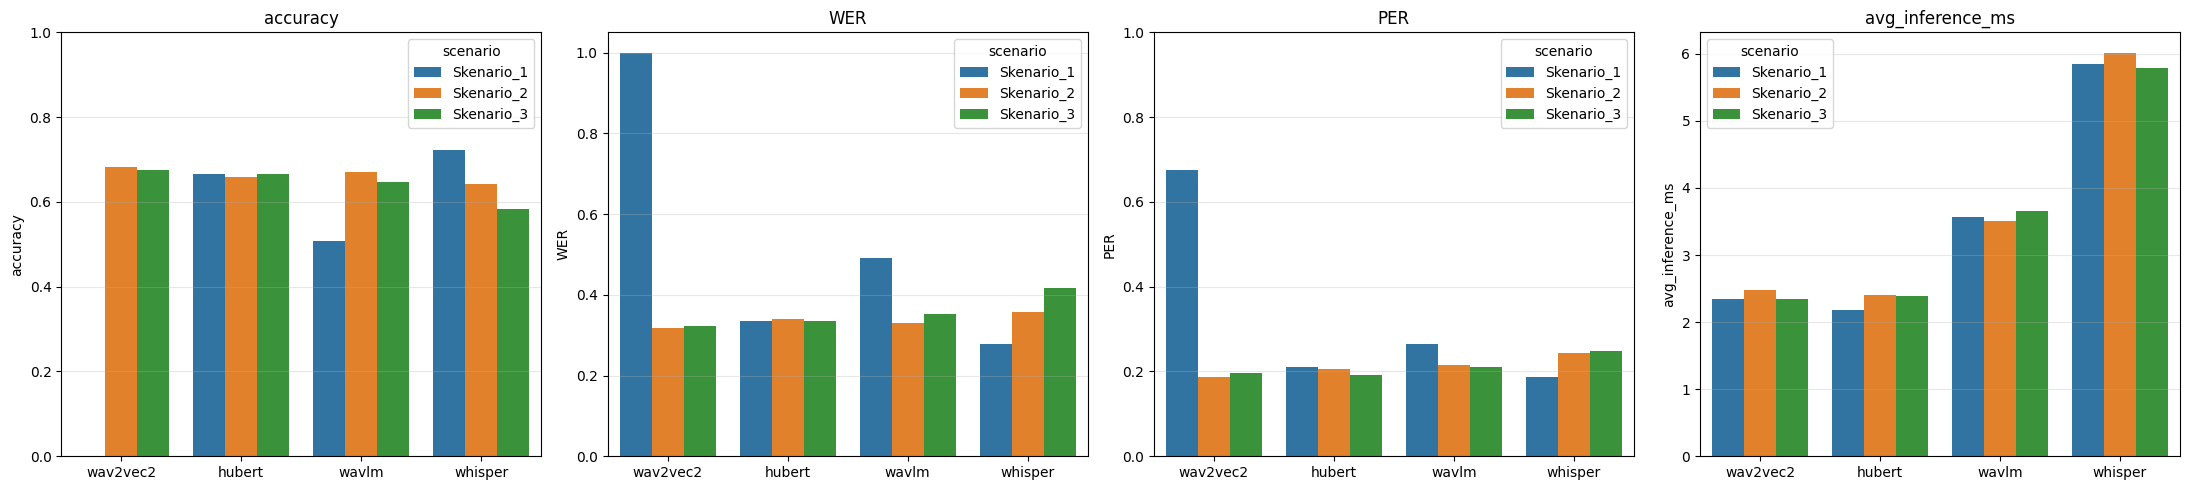

In [ ]:
# ============================================================
# [CELL 9] COMPARATIVE SUMMARY DASHBOARD (semua skenario x semua model di Drive)
# ============================================================
MODEL_ORDER, SCENARIO_ORDER = list(MODEL_REGISTRY), list(SCENARIOS)

# ---------- Status 12 eksperimen ----------
status_rows = []
for sc in SCENARIO_ORDER:
    for mk in MODEL_ORDER:
        P = exp_paths(mk, sc)
        if P['metrics_json'].exists():
            st = 'SELESAI'
        elif P['done'].exists():
            st = 'TRAINING SELESAI, BELUM EVALUASI'
        elif P['history'].exists():
            st = f'PARSIAL (epoch {len(pd.read_csv(P["history"]))}/{CONFIG["EPOCHS"]})'
        else:
            st = 'BELUM DIJALANKAN'
        status_rows.append({'scenario': sc, 'model': mk, 'status': st})
status_df = pd.DataFrame(status_rows).pivot(index='model', columns='scenario', values='status').reindex(MODEL_ORDER)
print('STATUS MATRIKS EKSPERIMEN')
display(status_df)

# ---------- Rekap metrik ----------
results = [json.load(open(f)) for f in sorted(OUTPUT_DIR.glob('Skenario_*/*/eval_metrics.json'))]
if not results:
    print('Belum ada eval_metrics.json. Jalankan CELL 8A / 8B / 8C terlebih dahulu.')
else:
    summary_df = pd.DataFrame(results)
    summary_df['scenario'] = pd.Categorical(summary_df['scenario'], SCENARIO_ORDER, ordered=True)
    summary_df['model'] = pd.Categorical(summary_df['model'], MODEL_ORDER, ordered=True)
    summary_df = summary_df.sort_values(['scenario', 'model']).reset_index(drop=True)
    cols = ['scenario', 'model', 'display_name', 'feature', 'accuracy', 'SER', 'WER', 'word_accuracy', 'CER', 'PER',
            'invalid_pred_rate', 'avg_inference_ms', 'best_epoch', 'epochs_run', 'train_minutes', 'n_test', 'hf_id']
    summary_df = summary_df[[c for c in cols if c in summary_df.columns]]
    metric_cols = ['accuracy', 'SER', 'WER', 'word_accuracy', 'CER', 'PER', 'invalid_pred_rate']
    display(summary_df.style.format({**{c: '{:.4f}' for c in metric_cols}, 'avg_inference_ms': '{:.2f}'})
            .highlight_max(subset=['accuracy', 'word_accuracy'], color='#c6efce')
            .highlight_min(subset=['WER', 'CER', 'PER'], color='#c6efce'))

    pivots = {}
    for metric in ['accuracy', 'WER', 'CER', 'PER', 'avg_inference_ms']:
        pv = summary_df.pivot_table(index='model', columns='scenario', values=metric, observed=False)
        pivots[metric] = pv
        print(f'\nPivot {metric} (baris = model, kolom = skenario)')
        display(pv.round(4))

    report_csv = OUTPUT_DIR / 'summary_final_report.csv'
    summary_df.to_csv(report_csv, index=False)
    with pd.ExcelWriter(OUTPUT_DIR / 'summary_final_report.xlsx') as w:
        summary_df.to_excel(w, sheet_name='summary', index=False)
        status_df.to_excel(w, sheet_name='status')
        for metric, pv in pivots.items():
            pv.to_excel(w, sheet_name=f'pivot_{metric}'[:31])
    print('Laporan disimpan:', report_csv, '| dan', OUTPUT_DIR / 'summary_final_report.xlsx')

    fig, axes = plt.subplots(1, 4, figsize=(22, 5))
    plot_df = summary_df.astype({'scenario': str, 'model': str})
    for ax, metric in zip(axes, ['accuracy', 'WER', 'PER', 'avg_inference_ms']):
        sns.barplot(data=plot_df, x='model', y=metric, hue='scenario', ax=ax,
                    order=[m for m in MODEL_ORDER if m in set(plot_df['model'])])
        ax.set_title(metric); ax.set_xlabel(''); ax.grid(axis='y', alpha=0.3)
        if metric != 'avg_inference_ms':
            ax.set_ylim(0, max(1.0, plot_df[metric].max() * 1.05))
    plt.tight_layout()
    plt.savefig(OUTPUT_DIR / 'summary_comparison.png', dpi=150, bbox_inches='tight'); plt.show(); plt.close()